| Subject Code | Assignment No. |
|:------------:|:--------------:|
| CS69101      | Lab 4          |

Given a set of integer elements stored in an input file, `input.txt`, construct a Red-Black Tree by inserting the elements one by one. Implement insertion and deletion operations while maintaining all the Red-Black Tree properties. Store the final tree contents in `output.txt` using in-order traversal.

In [1]:
import os
import sys
from io import TextIOWrapper
from typing import Self
import random
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pylab import figure

sys.setrecursionlimit(100000) # Fix to avoid RecursionError

os.makedirs("./lab4_data", exist_ok=True)

prep_arr = [random.randint(1, (i+1)*10) for i in range(10000)] # Random Array of 10000 Elements
# prep_arr.sort() # Sorted Array for Worst Case Scenario
print(prep_arr[:25])
print(len(prep_arr))

# Write the array to a file
f = open("./lab4_data/input0.txt", "w")
for i in prep_arr:
    f.write(f"{i}, ")
f.write("\n")
f.close()

del prep_arr
del f

iterations = 0
PRINT_DEBUG = False

[10, 12, 1, 22, 17, 59, 64, 44, 18, 78, 25, 68, 31, 70, 9, 90, 116, 62, 167, 10, 34, 97, 135, 184, 188]
10000


# Q1 & Q2

Read integer contents from `input.txt` and construct a Red-Black Tree using the `insert(key)` operation.

Implement Red-Black Tree insertion, including the required recolouring and LL, RR, LR, and RL rotations to maintain the Red-Black Tree properties.

## File Read

In [2]:
# Read a set of integer elements from an input file (input.txt)
arr0 = []
data0 = open("./lab4_data/input.txt", 'r')

try:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(' ','').split(',') #using rstrip to remove the \n
        for data in line_data:
            arr0.append(int(data))
    data0.close()
except Exception as e:
    sys.exit("[ERROR] Invalid data" + str(e))

print(f"Read {len(arr0)} elements.")

Read 17 elements.


In [3]:
print(arr0)

[70, 50, 90, 77, 55, 348, 76, 67, 69, 420, 25, 911, 210, 108, 768, 1080, 720]


## Red Black Tree

In [4]:
class RB_Node:
    def __init__(self, value: int | None = None) -> None:
        self.__value = value
        self.__lchild = None
        self.__rchild = None
        self.__parent = None
        self.__color = '#F00' # Color in #RGB, new node is always red

    def __get_lchild(self) -> Self | None:
        return self.__lchild

    def __set_lchild(self, lchild: Self | None) -> None: # type: ignore
        if PRINT_DEBUG:
            print(f"Setting left child of node with value {self.__value} to {lchild}")
        self.__lchild = lchild
        if lchild is not None:
            lchild.__parent = self

    lchild = property(__get_lchild, __set_lchild, doc="Left child of the node")

    def __get_rchild(self) -> Self | None:
        return self.__rchild

    def __set_rchild(self, rchild: Self | None) -> None: # type: ignore
        if PRINT_DEBUG:
            print(f"Setting right child of node with value {self.__value} to {rchild}")
        self.__rchild = rchild
        if rchild is not None:
            rchild.__parent = self

    rchild = property(__get_rchild, __set_rchild, doc="Right child of the node")

    def __get_parent(self) -> Self | None:
        return self.__parent

    def __set_parent(self, parent: Self | None) -> None: # type: ignore
        if PRINT_DEBUG:
            print(f"Setting parent of node with value {self.__value} to {parent}")
        self.__parent = parent

    parent = property(__get_parent, __set_parent, doc="Parent of the node")

    def __get_value(self) -> int | None:
        return self.__value

    def __set_value(self, value: int) -> None:
        self.__value = value

    value = property(__get_value, __set_value, doc="Value of the node")

    def __get_color(self) -> str | None:
        return self.__color

    def __set_color(self, color: str) -> None:
        self.__color = color

    color = property(__get_color, __set_color, doc="Color of the node")

    def __str__(self) -> str:
        return f"Node(value={self.__value}, color={self.__color}, lchild={self.__lchild.value if self.__lchild else None}, rchild={self.__rchild.value if self.__rchild else None}, parent={self.__parent.value if self.__parent else None})"

    def __repr__(self) -> str:
        return self.__str__()

In [5]:
def RB_right_rotate(k2_node: RB_Node | None, root_node: RB_Node | None) -> RB_Node | None:
    global iterations
    if PRINT_DEBUG:
        print(f"Right Rotate: k2_node={k2_node}, root_node={root_node}")
    k1_node = k2_node.lchild if k2_node is not None else None
    if k1_node is None or k2_node is None:
        return root_node

    iterations += 1
    if PRINT_DEBUG:
        print(f"LL Case: k1_node={k1_node}, k2_node={k2_node}")

    # From Weiss' Data Structures and Algorithm Analysis in C++ (Page 156)
    # Combined CLRS Logic with Weiss' Logic to avoid bugs

    # SAFETY CODE
    TEMP_NODE = k1_node.rchild
    OG_PARENT = k2_node.parent
    WAS_RCHILD = bool(OG_PARENT is not None and OG_PARENT.rchild is k2_node)

    # CLRS: x.lchild = y.rchild
    # CLRS: y.rchild = x
    k1_node.rchild = k2_node
    k2_node.lchild = TEMP_NODE

    # Update Parents

    # CLRS: if y.rchild is not None:
    # CLRS:     y.rchild.parent = y
    # CLRS: // However, y.rchild is now x.lchild, so we need to update x.lchild's parent to y
    if PRINT_DEBUG:
        print(f"Updating parent of {k2_node.lchild} to {k2_node}")
    if k2_node.lchild is not None:
        k2_node.lchild.parent = k2_node

    # CLRS: x.parent = y.parent
    k1_node.parent = OG_PARENT

    # CLRS: if y.parent is None:
    # CLRS:     root_node = y
    if OG_PARENT is None:
        root_node = k1_node
    # CLRS: elseif y is y.parent.rchild:
    # CLRS:     y.parent.rchild = x
    elif WAS_RCHILD:
        OG_PARENT.rchild = k1_node
    # CLRS: else:
    # CLRS:     y.parent.lchild = x
    else:
        OG_PARENT.lchild = k1_node


    # CLRS: y.parent = x
    # k2_node.parent = k1_node (THIS IS AUTO HANDLED BY SETTER METHOD)


    return root_node

In [6]:
def RB_left_rotate(k1_node: RB_Node | None, root_node: RB_Node | None) -> RB_Node | None:
    global iterations
    if PRINT_DEBUG:
        print(f"Left Rotate: k1_node={k1_node}, root_node={root_node}")
    k2_node = k1_node.rchild if k1_node is not None else None
    if k1_node is None or k2_node is None:
        return root_node

    iterations += 1
    if PRINT_DEBUG:
        print(f"RR Case: k1_node={k1_node}, k2_node={k2_node}")

    # From Weiss' Data Structures and Algorithm Analysis in C++ (Page 156)
    # Combined CLRS Logic with Weiss' Logic to avoid bugs

    # SAFETY CODE
    TEMP_NODE = k2_node.lchild
    OG_PARENT = k1_node.parent
    WAS_RCHILD = bool(OG_PARENT is not None and OG_PARENT.rchild is k1_node)

    # CLRS: x.rchild = y.lchild
    # CLRS: y.lchild = x
    k2_node.lchild = k1_node
    k1_node.rchild = TEMP_NODE

    # Update Parents

    # CLRS: if y.lchild is not None:
    # CLRS:     y.lchild.parent = x
    # CLRS: // However, y.lchild is now x.rchild, so we need to update x.rchild's parent to y
    if k1_node.rchild is not None:
        k1_node.rchild.parent = k1_node

    # CLRS: y.parent = x.parent
    k2_node.parent = OG_PARENT

    # CLRS: if x.parent is None:
    # CLRS:     root_node = y
    if OG_PARENT is None:
        root_node = k2_node
    # CLRS: elseif x is x.parent.lchild:
    # CLRS:     x.parent.lchild = y
    elif WAS_RCHILD:
        OG_PARENT.rchild = k2_node
    # CLRS: else:
    # CLRS:     x.parent.rchild = y
    else:
        OG_PARENT.lchild = k2_node

    # CLRS: x.parent = y
    # k1_node.parent = k2_node (THIS IS AUTO HANDLED BY SETTER METHOD)


    return root_node

In [7]:
def RB_Insert_Fixup(root: RB_Node, Z_Node: RB_Node) -> RB_Node | None:
    global iterations
    while Z_Node.parent is not None and Z_Node.parent.color == '#F00':
        iterations += 1
        if Z_Node.parent == Z_Node.parent.parent.lchild:
            Y_Node = Z_Node.parent.parent.rchild
            if Y_Node is not None and Y_Node.color == '#F00':
                Z_Node.parent.color = '#000'
                Y_Node.color = '#000'
                Z_Node.parent.parent.color = '#F00'
                Z_Node = Z_Node.parent.parent
            else:
                if Z_Node == Z_Node.parent.rchild:
                    Z_Node = Z_Node.parent
                    root = RB_left_rotate(Z_Node, root) # type: ignore
                Z_Node.parent.color = '#000'
                Z_Node.parent.parent.color = '#F00'
                root = RB_right_rotate(Z_Node.parent.parent, root) # type: ignore
        else:
            Y_Node = Z_Node.parent.parent.lchild
            if Y_Node is not None and Y_Node.color == '#F00':
                Z_Node.parent.color = '#000'
                Y_Node.color = '#000'
                Z_Node.parent.parent.color = '#F00'
                Z_Node = Z_Node.parent.parent
            else:
                if Z_Node == Z_Node.parent.lchild:
                    Z_Node = Z_Node.parent
                    root = RB_right_rotate(Z_Node, root) # type: ignore
                Z_Node.parent.color = '#000'
                Z_Node.parent.parent.color = '#F00'
                root = RB_left_rotate(Z_Node.parent.parent, root) # type: ignore
    root.color = '#000'
    return root

def RB_Insert(root: RB_Node | None, value: int) -> RB_Node | None:
    global iterations
    Z_Node = RB_Node(value)

    Y_NODE = None
    X_NODE = root
    while X_NODE is not None:
        iterations += 1
        Y_NODE = X_NODE
        if value < X_NODE.value:
            X_NODE = X_NODE.lchild
        else:
            X_NODE = X_NODE.rchild

    Z_Node.parent = Y_NODE

    if Y_NODE is None:
        root = Z_Node
    elif value < Y_NODE.value:
        Y_NODE.lchild = Z_Node
    else:
        Y_NODE.rchild = Z_Node

    # New Node's Color is already RED by default.

    root = RB_Insert_Fixup(root, Z_Node) # type: ignore
    return root

In [8]:
def RB_inorder_traversal(root: RB_Node | None, out_file: TextIOWrapper | None) -> None:
    if root is None:
        return
    RB_inorder_traversal(root.lchild, out_file = out_file)
    if out_file is not None:
        print(root.value, end = ', ', file = out_file)
    print(root.value, end = ', ')
    print(root)
    RB_inorder_traversal(root.rchild, out_file = out_file)

In [9]:
root0 = None
for value in arr0:
    root0 = RB_Insert(root0, value)

In [10]:
RB_inorder_traversal(root0, out_file = None)

25, Node(value=25, color=#F00, lchild=None, rchild=None, parent=50)
50, Node(value=50, color=#000, lchild=25, rchild=None, parent=55)
55, Node(value=55, color=#000, lchild=50, rchild=67, parent=70)
67, Node(value=67, color=#000, lchild=None, rchild=69, parent=55)
69, Node(value=69, color=#F00, lchild=None, rchild=None, parent=67)
70, Node(value=70, color=#000, lchild=55, rchild=420, parent=None)
76, Node(value=76, color=#F00, lchild=None, rchild=None, parent=77)
77, Node(value=77, color=#000, lchild=76, rchild=None, parent=90)
90, Node(value=90, color=#F00, lchild=77, rchild=210, parent=420)
108, Node(value=108, color=#F00, lchild=None, rchild=None, parent=210)
210, Node(value=210, color=#000, lchild=108, rchild=348, parent=90)
348, Node(value=348, color=#F00, lchild=None, rchild=None, parent=210)
420, Node(value=420, color=#000, lchild=90, rchild=911, parent=70)
720, Node(value=720, color=#F00, lchild=None, rchild=None, parent=768)
768, Node(value=768, color=#000, lchild=720, rchild=N

# Q3.

Implement delete(key) to remove a specified element from the tree and perform the required recolouring and rotations/fix-up operations.

## Deletion

In [11]:
def RB_Search(root: RB_Node | None, key: int) -> RB_Node | None:
    global iterations
    X_NODE = root
    while X_NODE is not None:
        iterations += 1
        if key == X_NODE.value:
            return X_NODE
        X_NODE = X_NODE.lchild if key < X_NODE.value else X_NODE.rchild
    return None


def RB_Minimum(node: RB_Node) -> RB_Node:
    global iterations
    while node.lchild is not None:
        iterations += 1
        node = node.lchild
    return node


def RB_is_black(node: RB_Node | None) -> bool:
    # A missing (None) child is a black NIL leaf
    return node is None or node.color == '#000'


def RB_Transplant(root: RB_Node | None, u: RB_Node, v: RB_Node | None) -> RB_Node | None:
    global iterations
    iterations += 1
    # CLRS RB-TRANSPLANT: replace the subtree rooted at u with the subtree rooted at v
    if u.parent is None:
        root = v
        if v is not None:
            v.parent = None
    elif u is u.parent.lchild:
        u.parent.lchild = v   # setter also sets v.parent
    else:
        u.parent.rchild = v   # setter also sets v.parent
    return root

In [12]:
def RB_Delete_Fixup(root: RB_Node | None, x: RB_Node | None, x_parent: RB_Node | None) -> RB_Node | None:
    global iterations
    # x carries the extra black. x may be None (NIL), so its parent is tracked separately.
    while x is not root and RB_is_black(x):
        if x_parent is None:
            break
        iterations += 1
        if x is x_parent.lchild:
            W_Node = x_parent.rchild
            if W_Node is not None and W_Node.color == '#F00':        # Case 1: sibling red
                W_Node.color = '#000'
                x_parent.color = '#F00'
                root = RB_left_rotate(x_parent, root)
                W_Node = x_parent.rchild
            if RB_is_black(W_Node.lchild if W_Node is not None else None) and RB_is_black(W_Node.rchild if W_Node is not None else None):
                # Case 2: both nephews black (a missing sibling is treated as black)
                if W_Node is not None:
                    W_Node.color = '#F00'
                x = x_parent
                x_parent = x.parent
            else:
                if RB_is_black(W_Node.rchild if W_Node is not None else None):  # Case 3: far nephew black
                    if W_Node is not None and W_Node.lchild is not None:
                        W_Node.lchild.color = '#000'
                    if W_Node is not None:
                        W_Node.color = '#F00'
                        root = RB_right_rotate(W_Node, root)
                    W_Node = x_parent.rchild
                if W_Node is not None:
                    W_Node.color = x_parent.color                            # Case 4: far nephew red
                    x_parent.color = '#000'
                    if W_Node.rchild is not None:
                        W_Node.rchild.color = '#000'
                root = RB_left_rotate(x_parent, root)
                x = root
                x_parent = None
        else:                                                        # mirror image
            W_Node = x_parent.lchild
            if W_Node is not None and W_Node.color == '#F00':
                W_Node.color = '#000'
                x_parent.color = '#F00'
                root = RB_right_rotate(x_parent, root)
                W_Node = x_parent.lchild
            if RB_is_black(W_Node.lchild if W_Node is not None else None) and RB_is_black(W_Node.rchild if W_Node is not None else None):
                if W_Node is not None:
                    W_Node.color = '#F00'
                x = x_parent
                x_parent = x.parent
            else:
                if RB_is_black(W_Node.lchild if W_Node is not None else None):
                    if W_Node is not None and W_Node.rchild is not None:
                        W_Node.rchild.color = '#000'
                    if W_Node is not None:
                        W_Node.color = '#F00'
                        root = RB_left_rotate(W_Node, root)
                    W_Node = x_parent.lchild
                if W_Node is not None:
                    W_Node.color = x_parent.color
                    x_parent.color = '#000'
                    if W_Node.lchild is not None:
                        W_Node.lchild.color = '#000'
                root = RB_right_rotate(x_parent, root)
                x = root
                x_parent = None
    if x is not None:
        x.color = '#000'
    return root


def RB_Delete(root: RB_Node | None, key: int) -> RB_Node | None:
    Z_Node = RB_Search(root, key)
    if Z_Node is None:
        print(f"[WARN] Key {key} not found, nothing deleted")
        return root

    Y_Node = Z_Node
    Y_ORIG_COLOR = Y_Node.color

    if Z_Node.lchild is None:                    # 0 or 1 child (right)
        X_Node = Z_Node.rchild
        X_Parent = Z_Node.parent
        root = RB_Transplant(root, Z_Node, Z_Node.rchild)
    elif Z_Node.rchild is None:                  # 1 child (left)
        X_Node = Z_Node.lchild
        X_Parent = Z_Node.parent
        root = RB_Transplant(root, Z_Node, Z_Node.lchild)
    else:                                        # 2 children: use in-order successor
        Y_Node = RB_Minimum(Z_Node.rchild)
        Y_ORIG_COLOR = Y_Node.color
        X_Node = Y_Node.rchild
        if Y_Node.parent is Z_Node:
            X_Parent = Y_Node
        else:
            X_Parent = Y_Node.parent
            root = RB_Transplant(root, Y_Node, Y_Node.rchild)
            Y_Node.rchild = Z_Node.rchild
        root = RB_Transplant(root, Z_Node, Y_Node)
        Y_Node.lchild = Z_Node.lchild
        Y_Node.color = Z_Node.color

    # Keep the NIL child's parent valid for the fix-up when it exists.
    if X_Node is not None:
        X_Parent = X_Node.parent

    # Detach the removed node
    Z_Node.lchild = None
    Z_Node.rchild = None
    Z_Node.parent = None

    if Y_ORIG_COLOR == '#000':                   # only a removed black node breaks black-height
        root = RB_Delete_Fixup(root, X_Node, X_Parent)
    if root is not None:
        root.parent = None
    return root

In [13]:
def RB_Verify(root: RB_Node | None) -> int:
    # Returns node count; raises AssertionError if any Red-Black property is broken
    if root is None:
        return 0
    assert root.parent is None, "root has a parent"
    assert root.color == '#000', "root is not black"
    def rec(n, lo, hi):
        if n is None:
            return 0, 1
        assert lo <= n.value <= hi, f"BST order broken at {n.value}"
        assert n.color in ('#000', '#F00'), f"invalid color at {n.value}"
        if n.color == '#F00':
            assert RB_is_black(n.lchild) and RB_is_black(n.rchild), f"red-red at {n.value}"
        for c in (n.lchild, n.rchild):
            assert c is None or c.parent is n, f"bad parent link under {n.value}"
        cl, bl = rec(n.lchild, lo, n.value)
        cr, br = rec(n.rchild, n.value, hi)
        assert bl == br, f"black-height mismatch at {n.value}"
        return cl + cr + 1, bl + (1 if n.color == '#000' else 0)
    return rec(root, float('-inf'), float('inf'))[0]


def RB_Height(root: RB_Node | None) -> int:
    if root is None:
        return 0
    return max(RB_Height(root.lchild), RB_Height(root.rchild)) + 1


def RB_Inorder_Values(root: RB_Node | None) -> list[int]:
    if root is None:
        return []
    return RB_Inorder_Values(root.lchild) + [root.value] + RB_Inorder_Values(root.rchild)

In [14]:
root0 = RB_Delete(root0, 420)
RB_Verify(root0)

with open("./lab4_data/output.txt", "w") as out_file:
    RB_inorder_traversal(root0, out_file = out_file)

25, Node(value=25, color=#F00, lchild=None, rchild=None, parent=50)
50, Node(value=50, color=#000, lchild=25, rchild=None, parent=55)
55, Node(value=55, color=#000, lchild=50, rchild=67, parent=70)
67, Node(value=67, color=#000, lchild=None, rchild=69, parent=55)
69, Node(value=69, color=#F00, lchild=None, rchild=None, parent=67)
70, Node(value=70, color=#000, lchild=55, rchild=720, parent=None)
76, Node(value=76, color=#F00, lchild=None, rchild=None, parent=77)
77, Node(value=77, color=#000, lchild=76, rchild=None, parent=90)
90, Node(value=90, color=#F00, lchild=77, rchild=210, parent=720)
108, Node(value=108, color=#F00, lchild=None, rchild=None, parent=210)
210, Node(value=210, color=#000, lchild=108, rchild=348, parent=90)
348, Node(value=348, color=#F00, lchild=None, rchild=None, parent=210)
720, Node(value=720, color=#000, lchild=90, rchild=911, parent=70)
768, Node(value=768, color=#000, lchild=None, rchild=None, parent=911)
911, Node(value=911, color=#F00, lchild=768, rchild=1

# Q6

For different numbers of nodes, such as 100, 500, 1000, 5000 and 10000, measure and plot:

- Tree Height vs. Number of Nodes
- Insertion Time vs. Number of Nodes
- Deletion Time vs. Number of Nodes
- Search Time vs. Number of Nodes

The operation cost is measured using iteration/computation counts.

**Method.** As in lab 3, one window of 10000 consecutive elements, starting at a random index of `input0.txt`, is inserted one by one and everything is recorded after every insertion: the tree height, the iterations of the insertion and the iterations of a search for a random, already inserted key. Every size from 1 to 10000 is therefore measured once. Deletion is recorded the same way: afterwards all elements are deleted in random order and the iterations of every deletion are stored together with the size of the tree it was performed on.

In [15]:
arr1 = []
with open("./lab4_data/input0.txt", 'r') as data0:
    for line in data0.readlines():
        line_data = line.rstrip().rstrip(',').replace(' ','').split(',')
        for data in line_data:
            arr1.append(int(data))

In [16]:
SIZES = [100, 500, 1000, 5000, 10000]
N = SIZES[-1]

random.seed(911)

def RB_Build_Measured(values: list[int]):
    global iterations
    root = None
    insert_counts = []
    for value in values:
        iterations = 0
        root = RB_Insert(root, value)
        insert_counts.append(iterations)
    return root, insert_counts


def RB_Search_Measured(root: RB_Node | None, key: int):
    global iterations
    iterations = 0
    node = RB_Search(root, key)
    return node, iterations


def RB_Delete_Measured(root: RB_Node | None, key: int):
    global iterations
    iterations = 0
    root = RB_Delete(root, key)
    return root, iterations


def RB_Recorded(values: list[int], search_idx: list[int], delete_keys: list[int]) -> dict:
    global iterations
    root = None
    height_store, insert_counts, search_counts, delete_counts = [], [], [], []
    for i, value in enumerate(values):
        iterations = 0
        root = RB_Insert(root, value)
        insert_counts.append(iterations)
        height_store.append(RB_Height(root))  # recorded once after every insertion, as in lab 3
        search_counts.append(RB_Search_Measured(root, values[search_idx[i]])[1])
    RB_Verify(root)

    for key in delete_keys:
        root, count = RB_Delete_Measured(root, key)
        delete_counts.append(count)
    assert root is None, "Red-Black Tree is not empty after deleting every element"

    # Deletions were recorded from the full tree downwards: reverse them so that index j belongs to size j + 1
    return {"Height": height_store, "Insertion": insert_counts, "Search": search_counts, "Deletion": delete_counts[::-1]}


def size_mean(series: list, n: int) -> float:
    # Mean of the values recorded for the last 10% of the sizes up to n (smooths the per-size noise)
    window = series[n - max(1, n // 10) : n]
    return sum(window) / len(window)


assert N <= len(arr1), "n cannot exceed the length of arr1"
start_idx = random.randint(0, len(arr1) - N)
random_values = arr1[start_idx : start_idx + N]

search_idx = [random.randrange(i + 1) for i in range(N)]  # step i searches one of the first i + 1 inserted elements
delete_keys = random_values[:]
random.shuffle(delete_keys)                                # every element is deleted once, in random order

records = {}
records[("Random", "Red-Black Tree")] = RB_Recorded(random_values, search_idx, delete_keys)

rb = records[("Random", "Red-Black Tree")]
task6_df = pd.DataFrame({
    "Nodes": SIZES,
    "Height": [rb["Height"][n - 1] for n in SIZES],
    "Insertion Iterations": [size_mean(rb["Insertion"], n) for n in SIZES],
    "Deletion Iterations": [size_mean(rb["Deletion"], n) for n in SIZES],
    "Search Iterations": [size_mean(rb["Search"], n) for n in SIZES],
})
print("Height at each size; iterations are the mean over the last 10% of the sizes up to that size")
print(task6_df)

Height at each size; iterations are the mean over the last 10% of the sizes up to that size
   Nodes  Height  Insertion Iterations  Deletion Iterations  Search Iterations
0    100       9                 9.000                8.700              6.200
1    500      12                11.200               11.280              7.800
2   1000      13                12.360               12.270              9.050
3   5000      15                14.608               14.434             11.400
4  10000      17                15.319               14.930             12.302


## Height v/s Node Count

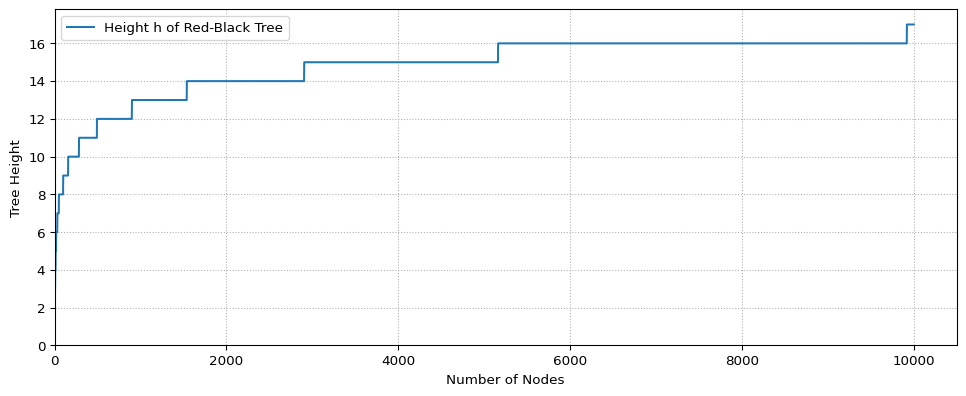

In [17]:
figure(figsize=(12, 4.5), dpi=97)
y = records[("Random", "Red-Black Tree")]["Height"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Height h of Red-Black Tree")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Nodes")
plt.ylabel("Tree Height")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab4_data/task6_height.png", dpi=150, bbox_inches="tight")
plt.show()

## Iterations (Insertion) v/s Node Count

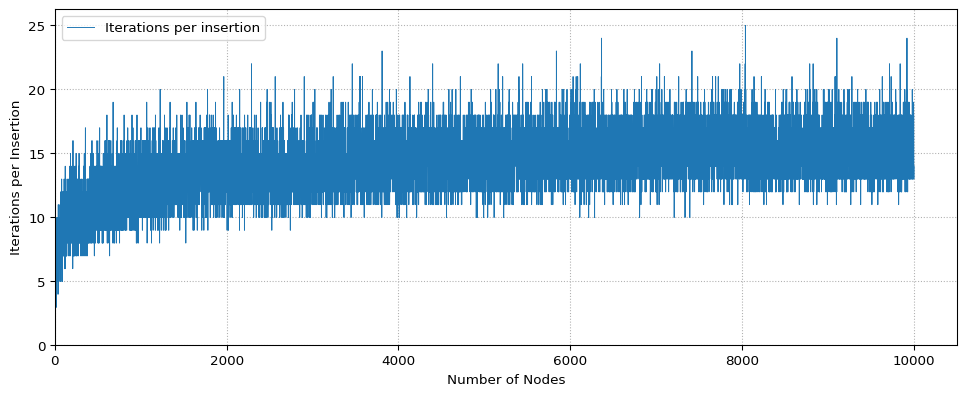

In [18]:
figure(figsize=(12, 4.5), dpi=97)
y = records[("Random", "Red-Black Tree")]["Insertion"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Iterations per insertion", linewidth=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Nodes")
plt.ylabel("Iterations per Insertion")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab4_data/task6_insertion.png", dpi=150, bbox_inches="tight")
plt.show()

## Iterations (Deletion) v/s Node Count

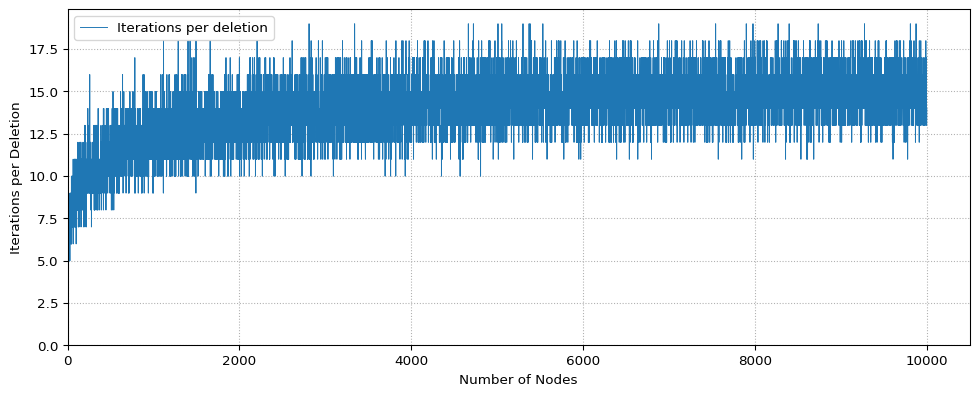

In [19]:
figure(figsize=(12, 4.5), dpi=97)
y = records[("Random", "Red-Black Tree")]["Deletion"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Iterations per deletion", linewidth=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Nodes")
plt.ylabel("Iterations per Deletion")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab4_data/task6_deletion.png", dpi=150, bbox_inches="tight")
plt.show()

## Iterations (Search) v/s Node Count

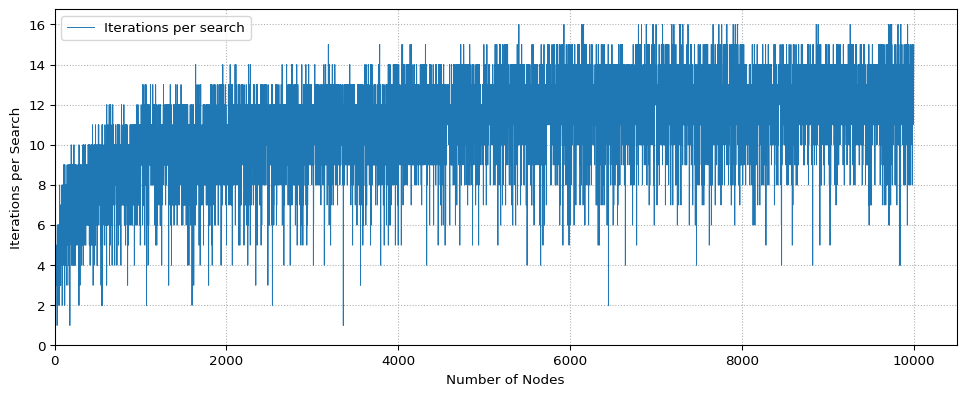

In [20]:
figure(figsize=(12, 4.5), dpi=97)
y = records[("Random", "Red-Black Tree")]["Search"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Iterations per search", linewidth=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Nodes")
plt.ylabel("Iterations per Search")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab4_data/task6_search.png", dpi=150, bbox_inches="tight")
plt.show()

## Save to CSV

In [21]:
task6_df.to_csv("./lab4_data/task6_summary.csv", index=False)

# The series plotted in the four graphs above, one row per number of nodes
task6_graph_df = pd.DataFrame({
    "Nodes": [i+1 for i in range(N)],
    "Height": records[("Random", "Red-Black Tree")]["Height"],
    "Iterations per Insertion": records[("Random", "Red-Black Tree")]["Insertion"],
    "Iterations per Deletion": records[("Random", "Red-Black Tree")]["Deletion"],
    "Iterations per Search": records[("Random", "Red-Black Tree")]["Search"],
})
task6_graph_df.to_csv("./lab4_data/task6_graph_data.csv", index=False)

# Q7

Implement an ordinary Binary Search Tree (BST) and experimentally compare its search time and height with the Red-Black Tree.

## BST Tree: All Code

In [22]:
class BST_Node:
    def __init__(self):
        self.lchild = None
        self.rchild = None
        self.value = None
        self.parent = None


def BST_Insert(value, root_node: BST_Node | None = None) -> BST_Node:
    assert value is not None, "Value cannot be None"
    y = None
    x = root_node
    global iterations
    while x is not None:
        iterations += 1
        y = x
        if value < x.value:
            x = x.lchild
        else:
            x = x.rchild
    new_node = BST_Node()
    new_node.value = value
    new_node.parent = y
    if y is None:
        root_node = new_node
    elif value < y.value:
        y.lchild = new_node
    else:
        y.rchild = new_node
    return root_node


def BST_Search(value, root_node: BST_Node | None = None) -> BST_Node | None:
    global iterations
    if root_node is None:
        return None
    iterations += 1
    if value == root_node.value:
        return root_node
    elif value < root_node.value:
        return BST_Search(value, root_node.lchild)
    else:
        return BST_Search(value, root_node.rchild)


def BST_minimum(root_node: BST_Node | None = None) -> BST_Node | None:
    global iterations
    if root_node is None:
        return None
    while root_node.lchild is not None:
        iterations += 1
        root_node = root_node.lchild
    return root_node


def BST_Transplant(root_node: BST_Node | None = None, target_node: BST_Node | None = None, replacement_node: BST_Node | None = None) -> BST_Node | None:
    global iterations
    iterations += 1
    if root_node is None:
        return None
    if target_node is None:
        return root_node
    if target_node.parent is None:
        root_node = replacement_node
    elif target_node == target_node.parent.lchild:
        target_node.parent.lchild = replacement_node
    else:
        target_node.parent.rchild = replacement_node
    if replacement_node is not None:
        replacement_node.parent = target_node.parent
    return root_node


def BST_Delete(root_node: BST_Node | None = None, target_node: BST_Node | None = None) -> BST_Node | None:
    global iterations
    iterations += 1
    if root_node is None:
        return None
    if target_node is None:
        return root_node
    if target_node.lchild is None:
        root_node = BST_Transplant(root_node, target_node, target_node.rchild)
    elif target_node.rchild is None:
        root_node = BST_Transplant(root_node, target_node, target_node.lchild)
    else:
        successor_node = BST_minimum(target_node.rchild)
        if successor_node.parent != target_node:
            root_node = BST_Transplant(root_node, successor_node, successor_node.rchild)
            successor_node.rchild = target_node.rchild
            successor_node.rchild.parent = successor_node
        root_node = BST_Transplant(root_node, target_node, successor_node)
        successor_node.lchild = target_node.lchild
        successor_node.lchild.parent = successor_node
    return root_node


def BST_Height(root_node: BST_Node | None = None) -> int:
    global iterations
    if root_node is None:
        return 0
    iterations += 1
    left_height = BST_Height(root_node.lchild)
    right_height = BST_Height(root_node.rchild)
    return max(left_height, right_height) + 1


def BST_Build_Measured(values: list[int]):
    global iterations
    root = None
    insert_counts = []
    for value in values:
        iterations = 0
        root = BST_Insert(value, root)
        insert_counts.append(iterations)
    return root, insert_counts


def BST_Search_Measured(root: BST_Node | None, key: int):
    global iterations
    iterations = 0
    node = BST_Search(key, root)
    return node, iterations


def BST_Delete_Measured(root: BST_Node | None, key: int):
    global iterations
    iterations = 0
    node = BST_Search(key, root)  # Include the search required to locate the target
    root = BST_Delete(root, node)
    return root, iterations


def BST_Inorder_Values(root: BST_Node | None) -> list[int]:
    if root is None:
        return []
    return BST_Inorder_Values(root.lchild) + [root.value] + BST_Inorder_Values(root.rchild)


def BST_Recorded(values: list[int], search_idx: list[int], delete_keys: list[int]) -> dict:
    global iterations
    root = None
    height_store, insert_counts, search_counts, delete_counts = [], [], [], []
    for i, value in enumerate(values):
        iterations = 0
        root = BST_Insert(value, root)
        insert_counts.append(iterations)
        height_store.append(BST_Height(root))  # recorded once after every insertion, as in lab 3
        search_counts.append(BST_Search_Measured(root, values[search_idx[i]])[1])

    for key in delete_keys:
        root, count = BST_Delete_Measured(root, key)
        delete_counts.append(count)
    assert root is None, "BST is not empty after deleting every element"

    return {"Height": height_store, "Insertion": insert_counts, "Search": search_counts, "Deletion": delete_counts[::-1]}


## Experiment

In [23]:
records[("Random", "BST")] = BST_Recorded(random_values, search_idx, delete_keys)

bst = records[("Random", "BST")]
task7_df = pd.DataFrame({
    "Nodes": SIZES,
    "BST Height": [bst["Height"][n - 1] for n in SIZES],
    "Red-Black Tree Height": [rb["Height"][n - 1] for n in SIZES],
})
task7_df

,Nodes,BST Height,Red-Black Tree Height
0,100,27,9
1,500,56,12
2,1000,77,13
3,5000,169,15
4,10000,235,17


## Height Comparison

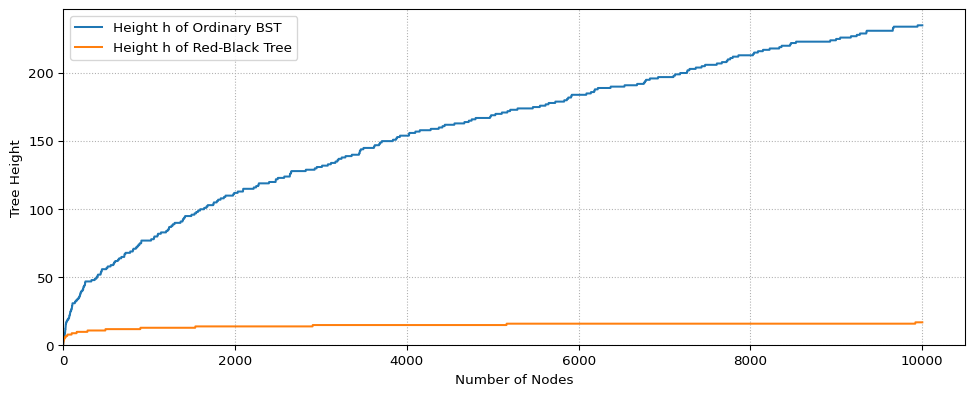

In [24]:
figure(figsize=(12, 4.5), dpi=97)
y = records[("Random", "BST")]["Height"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Height h of Ordinary BST")
y = records[("Random", "Red-Black Tree")]["Height"]
x = [i+1 for i in range(len(y))]
plt.plot(x, y, label="Height h of Red-Black Tree")
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.legend()
plt.xlabel("Number of Nodes")
plt.ylabel("Tree Height")
plt.grid(visible=True, linestyle=':')
plt.savefig("./lab4_data/task7_height.png", dpi=150, bbox_inches="tight")
plt.show()

## Search Comparison
The search comparison is measured for every size separately: a tree is built for each size, then 100 random successful searches are averaged.

In [25]:
task7_search_rows = []
for n in SIZES:
    assert n <= len(arr1), "n cannot exceed the length of arr1"
    start_idx = random.randint(0, len(arr1) - n)
    values = arr1[start_idx : start_idx + n]
    bst_root, _ = BST_Build_Measured(values)
    rb_root, _ = RB_Build_Measured(values)
    RB_Verify(rb_root)

    search_keys = random.sample(values, min(100, n))
    bst_search = [BST_Search_Measured(bst_root, key)[1] for key in search_keys]
    rb_search = [RB_Search_Measured(rb_root, key)[1] for key in search_keys]

    task7_search_rows.append({
        "Nodes": n,
        "BST Average Search Iterations": sum(bst_search) / len(bst_search),
        "Red-Black Tree Average Search Iterations": sum(rb_search) / len(rb_search),
    })

task7_search_df = pd.DataFrame(task7_search_rows)
task7_search_df

,Nodes,BST Average Search Iterations,Red-Black Tree Average Search Iterations
0,100,7.56,5.98
1,500,11.83,8.11
2,1000,15.34,9.36
3,5000,29.11,11.25
4,10000,116.41,12.50


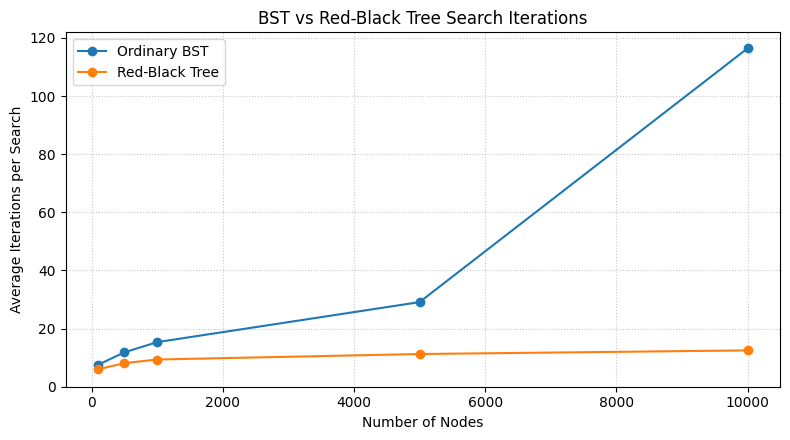

In [26]:
plt.figure(figsize=(8, 4.5))
plt.plot(task7_search_df["Nodes"], task7_search_df["BST Average Search Iterations"], marker="o", label="Ordinary BST")
plt.plot(task7_search_df["Nodes"], task7_search_df["Red-Black Tree Average Search Iterations"], marker="o", label="Red-Black Tree")
plt.xlabel("Number of Nodes")
plt.ylabel("Average Iterations per Search")
plt.ylim(bottom=0)
plt.title("BST vs Red-Black Tree Search Iterations")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.savefig("./lab4_data/task7_search.png", dpi=150, bbox_inches="tight")
plt.show()

## Save to CSV

In [27]:
task7_df.to_csv("./lab4_data/task7_height_summary.csv", index=False)

# The series plotted in the height comparison, one row per number of nodes
task7_graph_df = pd.DataFrame({
    "Nodes": [i+1 for i in range(N)],
    "BST Height": records[("Random", "BST")]["Height"],
    "Red-Black Tree Height": records[("Random", "Red-Black Tree")]["Height"],
})
task7_graph_df.to_csv("./lab4_data/task7_height_graph_data.csv", index=False)

task7_search_df.to_csv("./lab4_data/task7_search.csv", index=False)

# Q8

Experiment using random, sorted, and reverse-sorted input data and provide a brief analysis of the results.

The same 10000 values (and the same search positions and deletion order) are used for all three input orders. As in Q6, the height, insertion, search and deletion iterations are recorded for every size from 1 to 10000 (the random order was already recorded above). The search comparison is again measured for every size separately. The graphs and measurements are analysed below.

In [28]:
sorted_values = sorted(random_values)
input_orders = {
    "Sorted": sorted_values,
    "Reverse Sorted": list(reversed(sorted_values)),
}
for order_name, values in input_orders.items():
    records[(order_name, "BST")] = BST_Recorded(values, search_idx, delete_keys)
    records[(order_name, "Red-Black Tree")] = RB_Recorded(values, search_idx, delete_keys)

task8_rows = []
for order_name in ["Random", "Sorted", "Reverse Sorted"]:
    for tree_name in ["BST", "Red-Black Tree"]:
        rec = records[(order_name, tree_name)]
        task8_rows.append({
            "Nodes": N,
            "Input Order": order_name,
            "Tree": tree_name,
            "Height": rec["Height"][N - 1],
            "Insertion Iterations": size_mean(rec["Insertion"], N),
            "Deletion Iterations": size_mean(rec["Deletion"], N),
            "Search Iterations": size_mean(rec["Search"], N),
        })

task8_df = pd.DataFrame(task8_rows)
print("Values at 10000 nodes; iterations are the mean over the last 10% of the sizes")
task8_df

Values at 10000 nodes; iterations are the mean over the last 10% of the sizes


,Nodes,Input Order,Tree,Height,Insertion Iterations,Deletion Iterations,Search Iterations
0,10000,Random,BST,235,160.979,116.975,112.132
1,10000,Random,Red-Black Tree,17,15.319,14.930,12.302
2,10000,Sorted,BST,10000,9499.500,4700.194,4781.149
3,10000,Sorted,Red-Black Tree,24,27.000,16.789,12.606
4,10000,Reverse Sorted,BST,9089,8700.854,4530.937,4504.123
5,10000,Reverse Sorted,Red-Black Tree,24,26.790,16.774,12.633


## Height Comparison

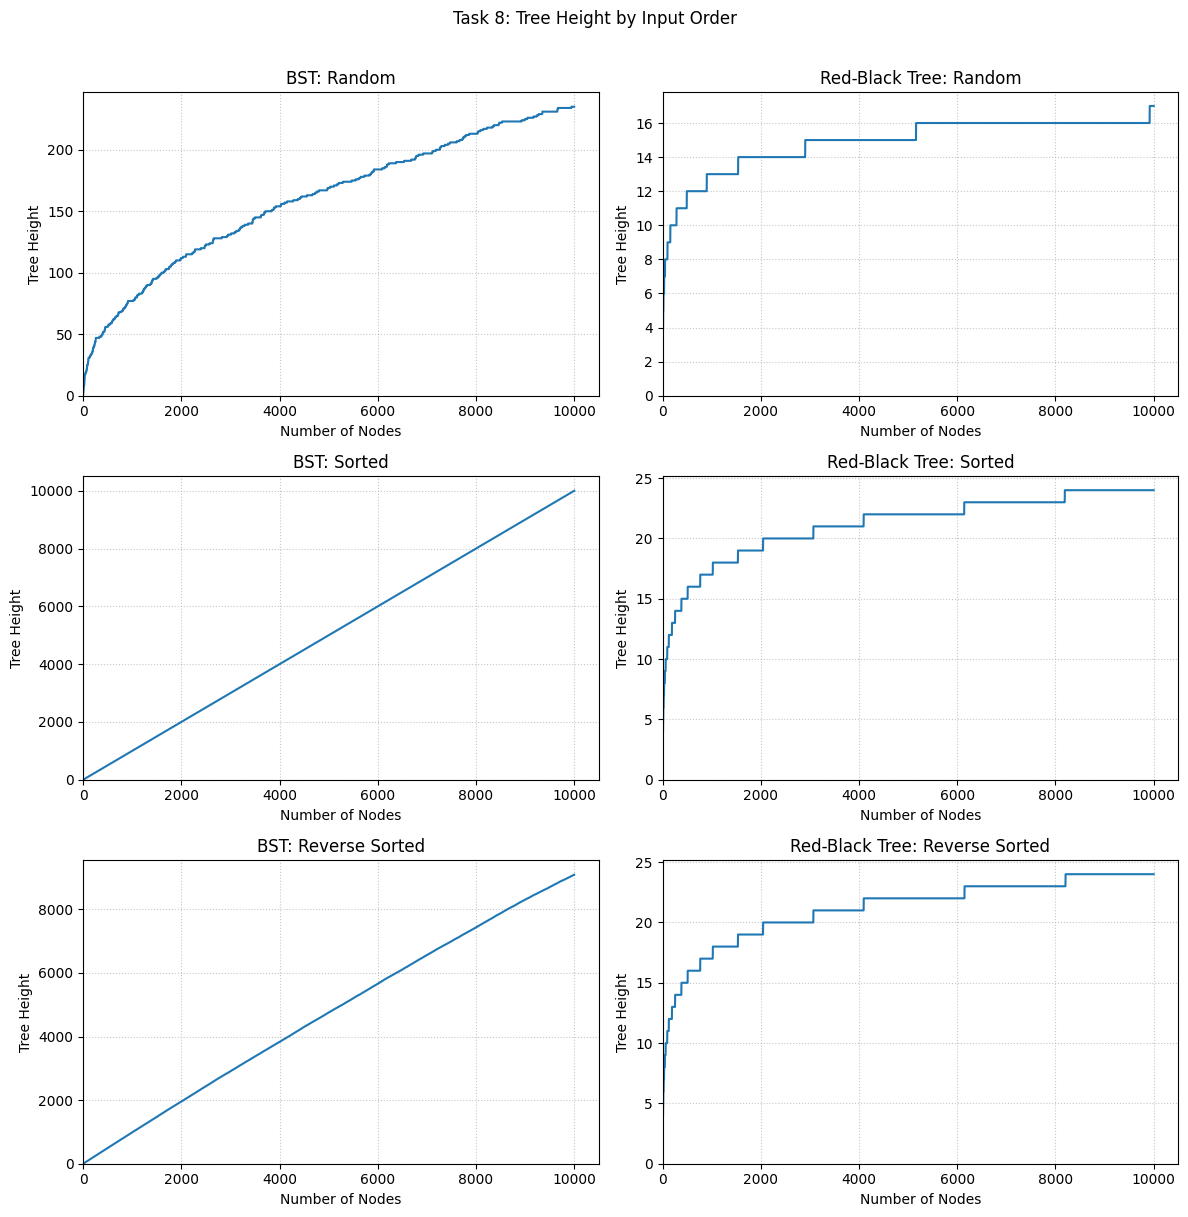

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, order_name in enumerate(["Random", "Sorted", "Reverse Sorted"]):
    for col_idx, tree_name in enumerate(["BST", "Red-Black Tree"]):
        ax = axes[row, col_idx]
        y = records[(order_name, tree_name)]["Height"]
        x = [i+1 for i in range(len(y))]
        ax.plot(x, y)
        ax.set_title(f"{tree_name}: {order_name}")
        ax.set_xlabel("Number of Nodes")
        ax.set_ylabel("Tree Height")
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 8: Tree Height by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab4_data/task8_height.png", dpi=150, bbox_inches="tight")
plt.show()

## Insertion Comparison

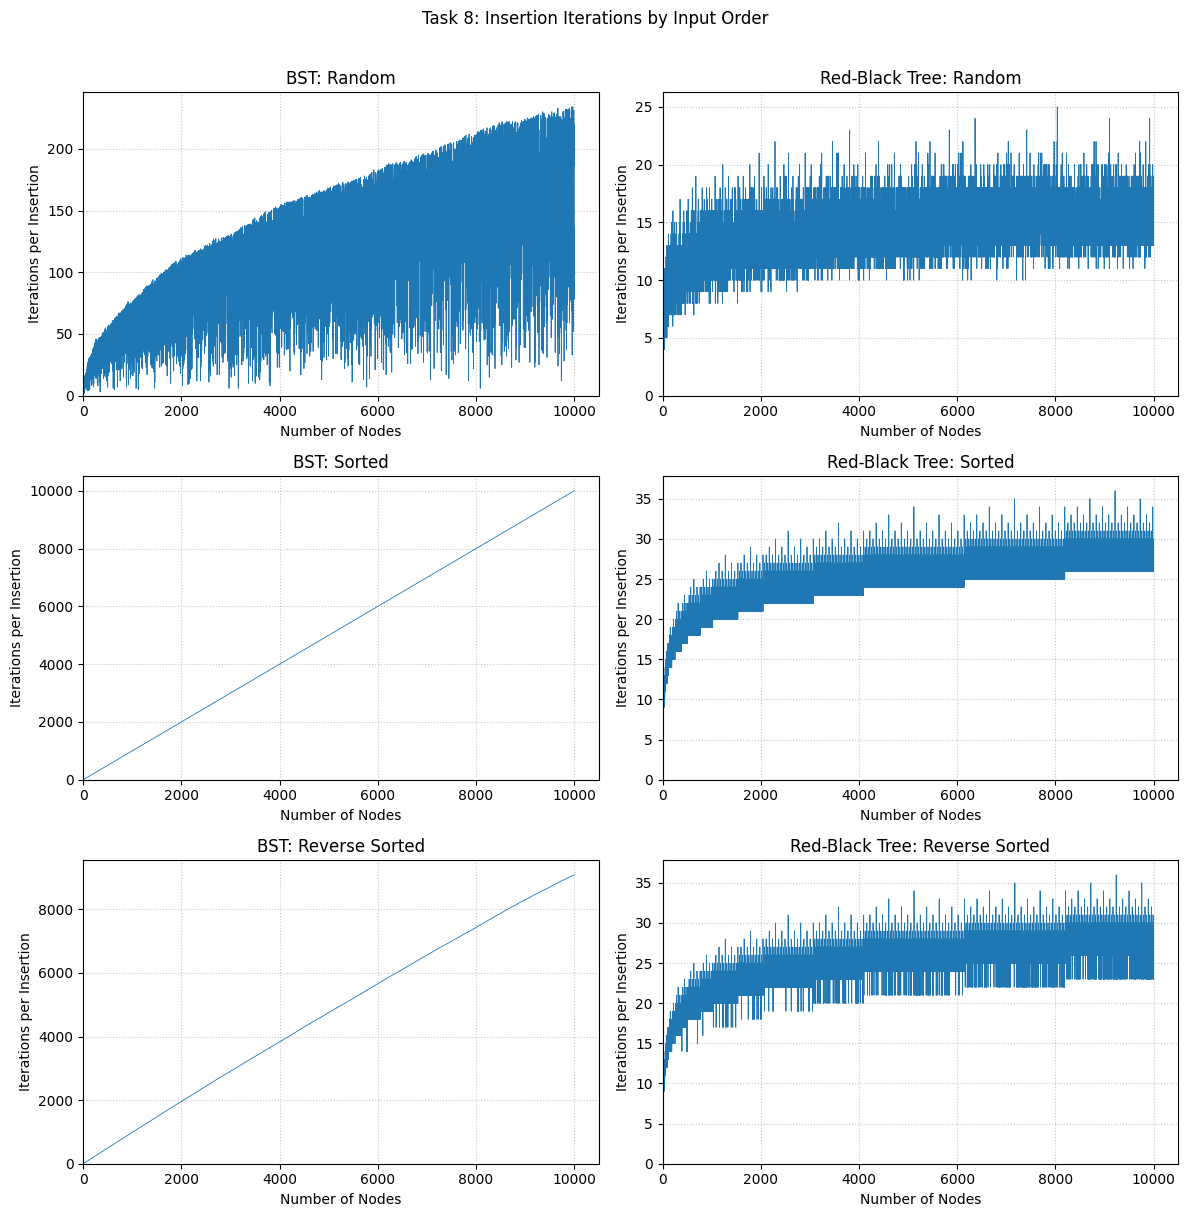

In [30]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, order_name in enumerate(["Random", "Sorted", "Reverse Sorted"]):
    for col_idx, tree_name in enumerate(["BST", "Red-Black Tree"]):
        ax = axes[row, col_idx]
        y = records[(order_name, tree_name)]["Insertion"]
        x = [i+1 for i in range(len(y))]
        ax.plot(x, y, linewidth=0.6)
        ax.set_title(f"{tree_name}: {order_name}")
        ax.set_xlabel("Number of Nodes")
        ax.set_ylabel("Iterations per Insertion")
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 8: Insertion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab4_data/task8_insertion.png", dpi=150, bbox_inches="tight")
plt.show()

## Deletion Comparison

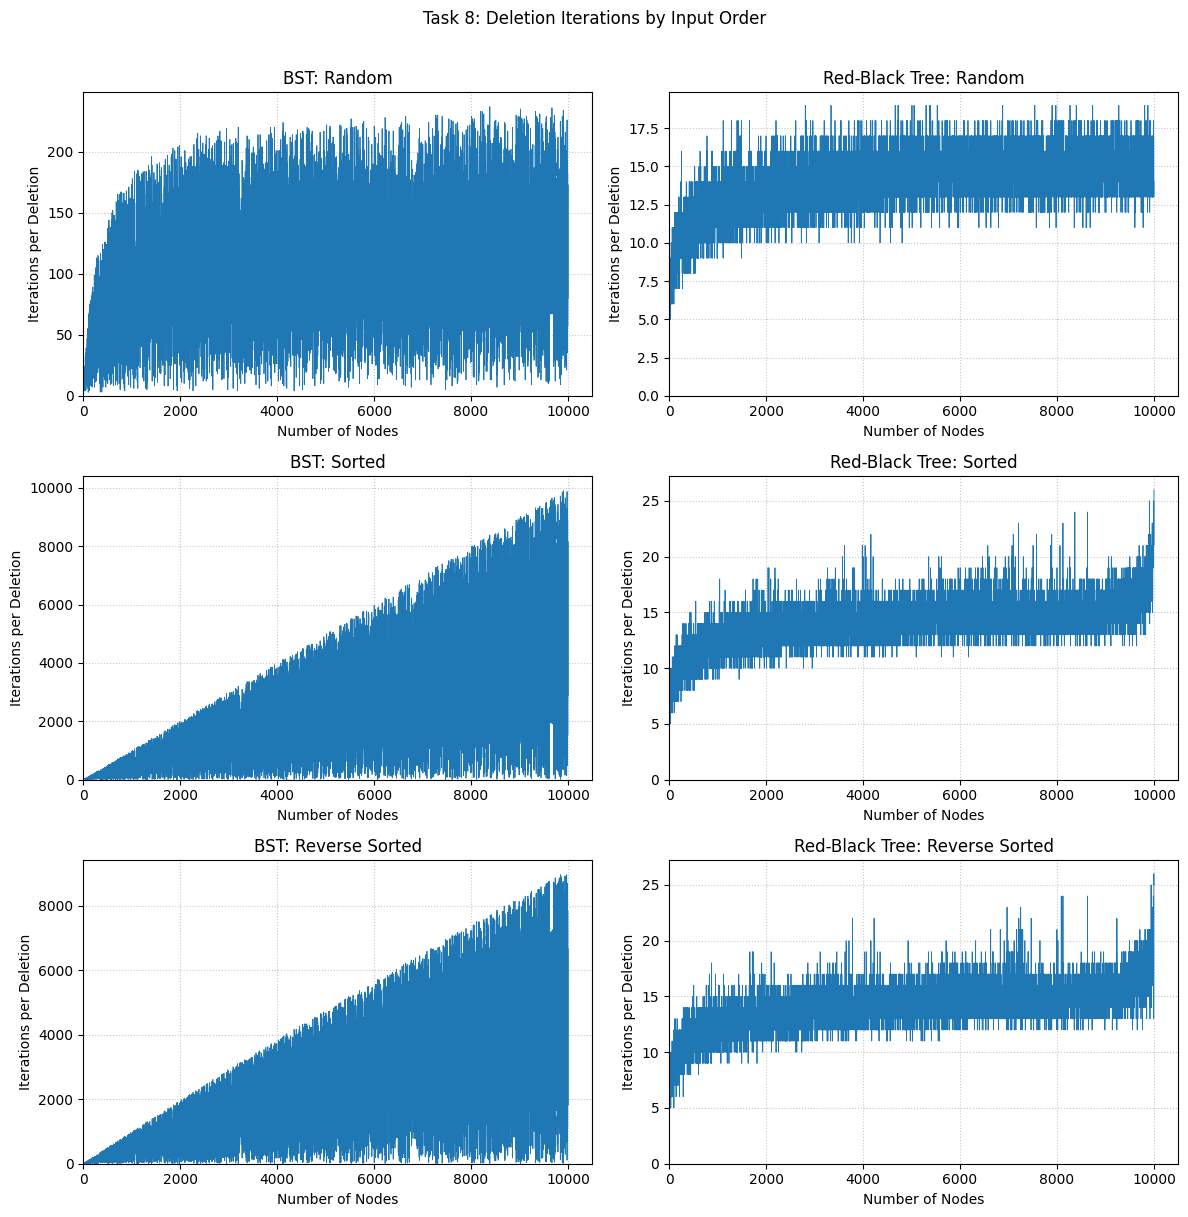

In [31]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, order_name in enumerate(["Random", "Sorted", "Reverse Sorted"]):
    for col_idx, tree_name in enumerate(["BST", "Red-Black Tree"]):
        ax = axes[row, col_idx]
        y = records[(order_name, tree_name)]["Deletion"]
        x = [i+1 for i in range(len(y))]
        ax.plot(x, y, linewidth=0.6)
        ax.set_title(f"{tree_name}: {order_name}")
        ax.set_xlabel("Number of Nodes")
        ax.set_ylabel("Iterations per Deletion")
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 8: Deletion Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab4_data/task8_deletion.png", dpi=150, bbox_inches="tight")
plt.show()

## Search Comparison
Measured for every size separately (a tree per size and input order, 100 random successful searches averaged).

In [32]:
task8_search_rows = []
for n in SIZES:
    assert n <= len(arr1), "n cannot exceed the length of arr1"
    start_idx = random.randint(0, len(arr1) - n)
    random_window = arr1[start_idx : start_idx + n]
    sorted_window = sorted(random_window)
    window_orders = {
        "Random": random_window,
        "Sorted": sorted_window,
        "Reverse Sorted": list(reversed(sorted_window)),
    }
    search_keys = random.sample(sorted_window, min(100, n))

    for order_name, values in window_orders.items():
        for tree_name in ["BST", "Red-Black Tree"]:
            if tree_name == "BST":
                root, _ = BST_Build_Measured(values)
                search_counts = [BST_Search_Measured(root, key)[1] for key in search_keys]
            else:
                root, _ = RB_Build_Measured(values)
                RB_Verify(root)
                search_counts = [RB_Search_Measured(root, key)[1] for key in search_keys]

            task8_search_rows.append({
                "Nodes": n,
                "Input Order": order_name,
                "Tree": tree_name,
                "Average Search Iterations": sum(search_counts) / len(search_counts),
            })

task8_search_df = pd.DataFrame(task8_search_rows)
task8_search_df

,Nodes,Input Order,Tree,Average Search Iterations
0,100,Random,BST,7.48
1,100,Random,Red-Black Tree,5.91
2,100,Sorted,BST,50.50
3,100,Sorted,Red-Black Tree,6.20
4,100,Reverse Sorted,BST,50.50
5,100,Reverse Sorted,Red-Black Tree,6.20
6,500,Random,BST,10.14
7,500,Random,Red-Black Tree,8.24
8,500,Sorted,BST,247.00
9,500,Sorted,Red-Black Tree,8.42


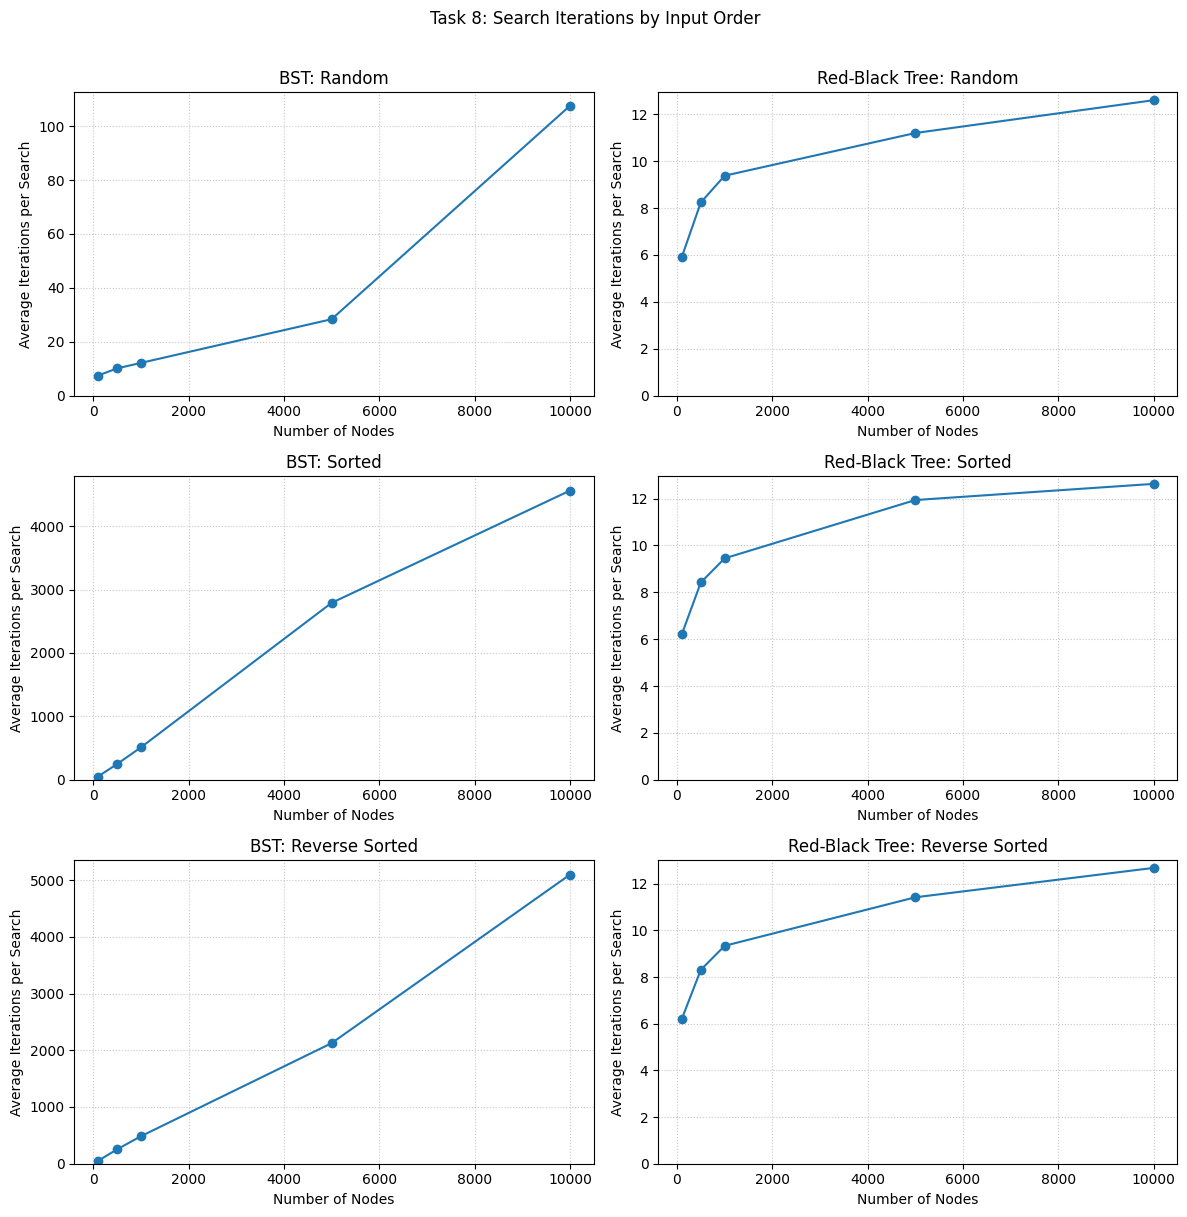

In [33]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, order_name in enumerate(["Random", "Sorted", "Reverse Sorted"]):
    for col_idx, tree_name in enumerate(["BST", "Red-Black Tree"]):
        ax = axes[row, col_idx]
        subset = task8_search_df[(task8_search_df["Input Order"] == order_name) & (task8_search_df["Tree"] == tree_name)]
        ax.plot(subset["Nodes"], subset["Average Search Iterations"], marker="o")
        ax.set_title(f"{tree_name}: {order_name}")
        ax.set_xlabel("Number of Nodes")
        ax.set_ylabel("Average Iterations per Search")
        ax.set_ylim(bottom=0)
        ax.grid(True, linestyle=":", alpha=0.7)
fig.suptitle("Task 8: Search Iterations by Input Order", y=1.01)
plt.tight_layout()
plt.savefig("./lab4_data/task8_search.png", dpi=150, bbox_inches="tight")
plt.show()

## Save to CSV

In [34]:
task8_df.to_csv("./lab4_data/task8_summary.csv", index=False)

# The series plotted in the height, insertion and deletion grids, one row per input order, tree and number of nodes
task8_graph_df = pd.DataFrame([
    {"Input Order": order_name, "Tree": tree_name, "Nodes": i+1,
     "Height": rec["Height"][i], "Iterations per Insertion": rec["Insertion"][i],
     "Iterations per Deletion": rec["Deletion"][i], "Iterations per Search": rec["Search"][i]}
    for (order_name, tree_name), rec in records.items() for i in range(N)
])
task8_graph_df.to_csv("./lab4_data/task8_graph_data.csv", index=False)

task8_search_df.to_csv("./lab4_data/task8_search.csv", index=False)

## Analysis

Costs are iteration counts. The height, insertion, deletion and search curves were recorded for every size from 1 to 10000 (one window of `input0.txt`, the same values, search positions and deletion order for all input orders). The table below uses the values at 10000 nodes; insertion, deletion and search iterations are the mean over the last 10 % of the sizes, because a single operation is noisy. The search comparison of Q7/Q8 was measured separately for every size.

| Input order | Tree | Height | Insertion | Deletion | Search (per size) | Search (100 keys, own tree) |
|:--|:--|--:|--:|--:|--:|--:|
| Random | BST | 235 | 161.0 | 117.0 | 112.1 | 107.5 |
| Random | Red-Black | 17 | 15.3 | 14.9 | 12.3 | 12.6 |
| Sorted | BST | 10000 | 9499.5 | 4700.2 | 4781.1 | 4562.0 |
| Sorted | Red-Black | 24 | 27.0 | 16.8 | 12.6 | 12.6 |
| Reverse sorted | BST | 9089 | 8700.9 | 4530.9 | 4504.1 | 5094.9 |
| Reverse sorted | Red-Black | 24 | 26.8 | 16.8 | 12.6 | 12.7 |

* **The BST depends heavily on the input order.** For sorted input the height grows like the line *y* = *x* (it is exactly *n*), inserting the *k*-th element costs exactly *k* - 1 iterations, and a search or a deletion costs about *k*/2, i.e. O(*n*) per operation. Reverse-sorted input behaves the same way, but its height is only 9089 because the window contains repeated values, and an equal key is inserted as the right child of the existing one, which breaks the chain slightly.
* **The Red-Black Tree is insensitive to the input order.** Its height curve is a slowly rising step function (like the AVL curve of lab 3): 17 levels for random and 24 for sorted or reverse-sorted input at 10000 nodes. Insertion, deletion and search cost between 12 and 27 iterations at that size. At 10000 nodes inserting the next sorted element is about 350 times cheaper, and a search about 360 times cheaper, than in the BST.
* **Sorted input is the Red-Black Tree's most expensive case, but only mildly.** Ascending (or descending) keys always extend the same side of the tree, so the tree is taller than for random keys (24 vs. 17 levels) and an insertion costs more (27.0 vs. 15.3 iterations), while the cost stays logarithmic. Sorted and reverse-sorted input give almost identical Red-Black results since the two trees are mirror images.
* **The per-operation curves are bands, not lines.** The cost of one insertion, deletion or search depends on the depth of the position it touches, so single operations scatter between a small value and roughly the current tree height; the upper edge of every band follows the height curve. This is why the table uses means.
* **The "random" BST is far from the textbook logarithmic case.** Its height reaches 235 and a search costs about 110 iterations at 10000 nodes. The reason is the data and not the tree: element *i* of `input0.txt` is drawn from `[1, 10(i + 1)]`, so later elements tend to be larger and every window is a partly increasing sequence, which pushes the BST towards the sorted case. With values drawn from one fixed range, the random-order BST height at 10000 nodes was about 31 in a separate check.
* **Caveats.** About 9 % of the values in `input0.txt` are repeated; each element is inserted as its own node, so every tree has exactly 10000 nodes. Only one window and one deletion order are used, and the search column "per size" uses one random key per size, so individual values fluctuate (the two search columns differ for that reason). Costs are iteration counts, not wall-clock times, and `input0.txt` is regenerated every time the first cell runs, so a rerun gives slightly different numbers.